# 15. Centaur input-range audit: DVEL, DVEL1, DVEL2, DVEL3 and RBLAB infrasound (2018–2020)

The infraBSU sensors were always recorded on Centaurs at one of two settings: **40 Vpp** (as for the
Trillium; nominally **18.4 counts/Pa**) or **1 Vpp** (×40 preamplifier; nominally **736 counts/Pa**).
`03_stationxml/KSC.xml` gives every DVEL*/RBLAB infrasound channel 18.4 counts/Pa, but launch peaks
corrected that way come out ≈ 40× too large (notebook 20). This notebook decides the setting for each
channel epoch from three independent lines of evidence:

1. **Metadata.** The master station sheet (`ksc_stations_master*.csv/xlsx`) leaves `vpp` blank for
   these rows, and flovopy's StationXML builder (`flovopy/stationmetadata/build.py`) turns any value
   other than 1 or 40 into 40. Response files exported by the Centaurs themselves record the
   preamplifier gain.
2. **Launch peaks in raw counts** at these stations against the beach-house reference channels of
   known setting: **BCHH1 DD2 (40 Vpp**, field notes: "1 infraBSU with 40 V full-scale") and
   **BCHH2 DD4–DD9 (1 Vpp)**, for every launch both recorded, reduced to a common distance (p·r).
3. **Ambient level**: night-time 0.15–0.35 Hz (microbarom band) RMS converted to Pa under each
   hypothesis; only one setting gives plausible pressures (~0.01–0.5 Pa).

Output: `03_stationxml/vpp_audit_DVEL_RBLAB.csv`, the proposed `vpp` per channel epoch, ready to go
into the master sheet before `KSC.xml` is rebuilt.

In [1]:
import sys, warnings, glob, zipfile, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from obspy import UTCDateTime, read_inventory
from obspy.clients.filesystem.sds import Client

PAPER_DIR = Path.cwd()
REPO_ROOT = PAPER_DIR.parent
sys.path.insert(0, str(REPO_ROOT / "ksclib" / "src"))
from ksclib import catalog_events as ce

warnings.filterwarnings("ignore", message="ObsPy can not map unit")
ens = ce.load_ensemble(PAPER_DIR / "ensemble.yaml")
ERA = ens.eras[0]
sds = Client(str(ERA.sds))
inv_ksc = read_inventory(str(ERA.stationxml))
OUT = ens.out_dir / "15_centaur_gain_audit"
OUT.mkdir(parents=True, exist_ok=True)
GAIN = {40: 18.4, 1: 736.0}          # counts/Pa, nominal infraBSU on a Centaur
HALDATA = Path("/Volumes/haldata/KSC")

## 1. Metadata

In [2]:
# 1a. What the master sheet says (the source KSC.xml was built from)
master = pd.read_csv(HALDATA / "station_metadata" / "ksc_stations_master.csv", encoding="utf-8-sig")
m = master[master.station.astype(str).str.match(r"(DVEL|RBLAB|BCHH1|BCHH2)$") & master.sensor.astype(str).str.contains("infraBSU|Chaparral")]
display(m[["network", "station", "location", "channel", "datalogger", "sensor", "vpp", "fsamp", "ondate", "offdate"]])

# 1b. What KSC.xml says now
rows = []
for net in inv_ksc.select(network="1R"):
    for sta in net:
        if not any(sta.code.startswith(p) for p in ("DVEL", "RBLAB")):
            continue
        for ch in sta:
            if ch.code[1] == "D":
                rows.append(dict(station=sta.code, channel=ch.code, start=str(ch.start_date)[:10], end=str(ch.end_date)[:10],
                                 sample_rate=ch.sample_rate, counts_per_Pa=ch.response.instrument_sensitivity.value))
display(pd.DataFrame(rows))

,network,station,location,channel,datalogger,sensor,vpp,fsamp,ondate,offdate
21,FL,DVEL,NaN,DD123,Centaur,infraBSU,NaN,250.0,2017-02-13,NaN
24,FL,BCHH1,10.0,DD4,Centaur,Chaparral,40.0,250.0,2017-08-18,2022-01-01
25,FL,BCHH1,10.0,DD5,Centaur,infraBSU,40.0,250.0,2017-08-18,2022-01-01
26,FL,BCHH2,0.0,DD1,Centaur,infraBSU,1.0,250.0,2017-08-18,2017-11-13
27,FL,BCHH2,0.0,DD2,Centaur,infraBSU,1.0,250.0,2017-08-18,2017-11-13
28,FL,BCHH2,0.0,DD3,Centaur,infraBSU,1.0,250.0,2017-08-18,2017-11-13
29,FL,BCHH2,10.0,DD456,Centaur,infraBSU,1.0,250.0,2017-08-18,2017-11-13
30,FL,BCHH2,0.0,DD4,Centaur,infraBSU,1.0,250.0,2017-11-15,2022-01-01
31,FL,BCHH2,0.0,DD5,Centaur,infraBSU,1.0,250.0,2017-11-15,2022-01-01
32,FL,BCHH2,0.0,DD6,Centaur,infraBSU,1.0,250.0,2017-11-15,2022-01-01


,station,channel,start,end,sample_rate,counts_per_Pa
0,DVEL,DD1,2017-02-13,2018-12-31,250.0,18.4
1,DVEL,DD2,2017-02-13,2018-12-31,250.0,18.4
2,DVEL,DD3,2017-02-13,2018-12-31,250.0,18.4
3,DVEL1,DD1,2018-02-06,2018-02-08,250.0,18.4
4,DVEL1,DD2,2018-02-06,2018-02-08,250.0,18.4
5,DVEL1,DD3,2018-02-06,2018-02-08,250.0,18.4
6,DVEL1,DD4,2018-02-06,2018-02-08,250.0,18.4
7,DVEL1,DD5,2018-02-06,2018-02-08,250.0,18.4
8,DVEL1,DD6,2018-02-06,2018-02-08,250.0,18.4
9,DVEL1,HD1,2018-02-06,2018-02-08,100.0,18.4


In [3]:
# 1c. Responses written by the Centaurs themselves: the stage after the sensor is the preamplifier
#     (gain 1 -> 40 Vpp input range; gain 40 -> 1 Vpp). BCHH1 (40 V full scale in the field notes) is the control.
def centaur_stages(paths):
    out = []
    for p in paths:
        try:
            inv = read_inventory(str(p))
        except Exception:
            continue
        for n in inv:
            for s in n:
                for ch in s:
                    st = ch.response.response_stages
                    out.append(dict(file=Path(p).name, station=s.code, channel=ch.code, written=str(ch.start_date)[:19],
                                    sensor_stage=st[0].stage_gain, preamp_gain=st[1].stage_gain,
                                    adc_counts_per_V=next((x.stage_gain for x in st if x.output_units.upper() == "COUNTS"), np.nan)))
    return pd.DataFrame(out)

tmp = Path(tempfile.mkdtemp())
zipfile.ZipFile(HALDATA / "responses" / "FL.BCHH1.0.dataless.zip").extractall(tmp)
stages = centaur_stages(sorted(glob.glob(str(HALDATA / "responses" / "FL.DVEL3.*.dataless"))) + sorted(glob.glob(str(tmp / "*.dataless"))))
stages["input_range_Vpp"] = np.where(np.isclose(stages.preamp_gain, 40), 1, np.where(np.isclose(stages.preamp_gain, 1, atol=0.01), 40, np.nan))
stages

,file,station,channel,written,sensor_stage,preamp_gain,adc_counts_per_V,input_range_Vpp
0,FL.DVEL3.HD1.dataless,DVEL3,HD1,2019-06-25T17:30:35,1.0,40.000000,400000.0,1.0
1,FL.DVEL3.HD2.dataless,DVEL3,HD2,2019-06-25T17:30:36,1.0,40.000000,400000.0,1.0
2,FL.DVEL3.HD3.dataless,DVEL3,HD3,2019-06-25T17:30:37,1.0,40.000000,400000.0,1.0
3,FL.DVEL3.HHE.dataless,DVEL3,HHE,2019-06-25T17:30:26,754.3,0.992542,400000.0,40.0
4,FL.DVEL3.HHN.dataless,DVEL3,HHN,2019-06-25T17:30:25,754.3,0.992542,400000.0,40.0
5,FL.DVEL3.HHZ.dataless,DVEL3,HHZ,2019-06-25T17:30:22,754.3,0.992542,400000.0,40.0
6,FL.DVEL3.LHE.dataless,DVEL3,LHE,2019-06-25T17:30:33,754.3,0.992542,400000.0,40.0
7,FL.DVEL3.LHN.dataless,DVEL3,LHN,2019-06-25T17:30:31,754.3,0.992542,400000.0,40.0
8,FL.DVEL3.LHZ.dataless,DVEL3,LHZ,2019-06-25T17:30:29,754.3,0.992542,400000.0,40.0
9,FL.BCHH1.0.HD1.dataless,BCHH1,HD1,2018-08-10T20:19:46,1.0,1.000000,400000.0,40.0


**Reading:** the DVEL3 dataless files (exported from Centaur 166 on 2019-06-25) carry a ×40
preamplifier stage on HD1–HD3 (the infrasound inputs, recorded as DD1–DD3 in the SDS), i.e. **1 Vpp**,
while its Trillium channels carry ×0.99 (40 Vpp). The BCHH1 control (2018-08-10) has ×1 on its
infrasound inputs, matching the field notes (40 V full scale). There are no Centaur-written responses
for DVEL1, DVEL2 or RBLAB (February 2018), so for those the waveforms decide.

## 2. Launch peaks in raw counts against the beach-house references

For each launch recorded by a test station and by BCHH1 DD2 and/or BCHH2 DD4–DD9: raw counts,
high-pass 0.5 Hz (the infraBSU response is flat there), peak |x| from 30 s before to 300 s after the
catalog time. Each peak is converted to Pa with the reference's documented gain and with both
candidate gains for the test channel, then reduced to p·r (Pa·km) with the distance from that
launch's pad. If a hypothesis is right, the ratio test/reference of p·r is of order 1 (directivity,
site and propagation spread it by a factor of a few); the wrong one is off by 40.

In [4]:
cat = ce.load_catalog(ens, extra=False)
TEST = {
    "DVEL1": ["DD1", "DD2", "DD3", "DD4", "DD5", "DD6"],
    "DVEL2": ["DD1", "DD2", "DD3"],
    "RBLAB": ["DD1", "DD2", "DD3"],
    "DVEL3": ["DD1", "DD2", "DD3"],
}
REFS = {("BCHH1", "DD2"): 40, **{("BCHH2", c): 1 for c in ("DD4", "DD5", "DD6", "DD7", "DD8", "DD9")}}

def peak_counts(sta, cha, t0, window=(-30, 300), noise=(-330, -30)):
    st = sds.get_waveforms("1R", sta, "*", cha, t0 + noise[0] - 20, t0 + window[1] + 20)
    if not st:
        return np.nan, np.nan
    st.merge(fill_value=0)
    tr = st[0]
    if tr.stats.npts < 100 * tr.stats.sampling_rate:
        return np.nan, np.nan
    tr.detrend("demean"); tr.taper(0.02)
    tr.filter("highpass", freq=0.5, corners=4, zerophase=True)
    t = tr.times(reftime=t0); x = np.abs(tr.data)
    s, n = (t >= window[0]) & (t <= window[1]), (t >= noise[0]) & (t < noise[1])
    if s.sum() < 0.9 * (window[1] - window[0]) * tr.stats.sampling_rate:
        return np.nan, np.nan
    return float(x[s].max()), float(x[n].max()) if n.any() else np.nan

rows = []
for _, r in cat.iterrows():
    t0 = UTCDateTime(r.event_time_utc)
    if not (UTCDateTime("2018-02-01") <= t0 <= UTCDateTime("2020-02-01")):
        continue
    try:
        ev = ce.event_from_row(r, ens)
    except Exception:
        continue
    tab = ce.station_table(ev)
    for (sta, cha) in [(s, c) for s, cs in TEST.items() for c in cs] + list(REFS):
        if sta not in tab.index and sta not in ("DVEL1", "DVEL2", "RBLAB", "DVEL3", "BCHH1", "BCHH2"):
            continue
        try:
            pk, nz = peak_counts(sta, cha, t0)
        except Exception:
            continue
        if np.isnan(pk):
            continue
        rows.append(dict(event_id=r.event_id, time=str(t0)[:16], vehicle=r.vehicle, pad=ev.site_name,
                         station=sta, channel=cha, distance_km=tab.distance_km.get(sta, np.nan),
                         peak_counts=pk, noise_counts=nz, snr=pk / nz if nz else np.nan))
peaks = pd.DataFrame(rows)
peaks.to_csv(OUT / "launch_peaks_counts.csv", index=False)
print(peaks.event_id.nunique(), "launches;", peaks.groupby("station").event_id.nunique().to_dict())

26 launches; {'BCHH1': 17, 'BCHH2': 19, 'DVEL1': 1, 'DVEL2': 1, 'DVEL3': 15, 'RBLAB': 1}


In [5]:
# Reference p*r per launch: median over good BCHH2 channels (1 Vpp) and BCHH1 DD2 (40 Vpp) separately
good = peaks[peaks.snr >= 5].copy()
ref_rows = []
for eid, g in good.groupby("event_id"):
    for ref_sta, vpp in (("BCHH2", 1), ("BCHH1", 40)):
        h = g[(g.station == ref_sta) & g.apply(lambda x: (x.station, x.channel) in REFS, axis=1)]
        if len(h):
            ref_rows.append(dict(event_id=eid, ref=ref_sta, ref_pr=float(np.median(h.peak_counts / GAIN[vpp] * h.distance_km))))
refs = pd.DataFrame(ref_rows).pivot(index="event_id", columns="ref", values="ref_pr")

test = good[good.station.isin(TEST)].join(refs, on="event_id")
for vpp in (40, 1):
    test[f"pr_if_{vpp}Vpp"] = test.peak_counts / GAIN[vpp] * test.distance_km
    for ref in ("BCHH2", "BCHH1"):
        if ref in test:
            test[f"ratio_{vpp}Vpp_vs_{ref}"] = test[f"pr_if_{vpp}Vpp"] / test[ref]
test["consistency_check_BCHH1_vs_BCHH2"] = test.get("BCHH1") / test.get("BCHH2")
cols = ["time", "vehicle", "pad", "station", "channel", "distance_km", "snr", "pr_if_40Vpp", "pr_if_1Vpp",
        "BCHH2", "BCHH1", "ratio_40Vpp_vs_BCHH2", "ratio_1Vpp_vs_BCHH2", "ratio_40Vpp_vs_BCHH1", "ratio_1Vpp_vs_BCHH1"]
test = test.sort_values(["station", "channel", "time"])
test.to_csv(OUT / "launch_ratio_table.csv", index=False)
test[[c for c in cols if c in test]].style.format(precision=2)

,time,vehicle,pad,station,channel,distance_km,snr,pr_if_40Vpp,pr_if_1Vpp,BCHH2,BCHH1,ratio_40Vpp_vs_BCHH2,ratio_1Vpp_vs_BCHH2,ratio_40Vpp_vs_BCHH1,ratio_1Vpp_vs_BCHH1
0,2018-02-06T20:45,Falcon Heavy,LC39A,DVEL1,DD1,3.28,102.76,2960.20,74.00,351.58,432.29,8.42,0.21,6.85,0.17
1,2018-02-06T20:45,Falcon Heavy,LC39A,DVEL1,DD2,3.28,1143.44,22773.23,569.33,351.58,432.29,64.77,1.62,52.68,1.32
2,2018-02-06T20:45,Falcon Heavy,LC39A,DVEL1,DD3,3.28,6.00,63.21,1.58,351.58,432.29,0.18,0.00,0.15,0.00
6,2018-02-06T20:45,Falcon Heavy,LC39A,DVEL2,DD1,3.39,216.40,8348.80,208.72,351.58,432.29,23.75,0.59,19.31,0.48
7,2018-02-06T20:45,Falcon Heavy,LC39A,DVEL2,DD2,3.39,135.88,16603.66,415.09,351.58,432.29,47.23,1.18,38.41,0.96
8,2018-02-06T20:45,Falcon Heavy,LC39A,DVEL2,DD3,3.39,425.02,4396.41,109.91,351.58,432.29,12.50,0.31,10.17,0.25
89,2019-04-11T22:35,Falcon Heavy,LC39A,DVEL3,DD1,3.29,199.60,14395.04,359.88,380.55,359.63,37.83,0.95,40.03,1.00
99,2019-05-04T06:48,Falcon 9,LC40,DVEL3,DD1,3.51,798.83,10587.52,264.69,289.23,nan,36.61,0.92,nan,nan
108,2019-05-24T02:30,Falcon 9,LC40,DVEL3,DD1,3.51,311.74,12864.46,321.61,277.71,nan,46.32,1.16,nan,nan
117,2019-07-02T11:00,Orion Test Booster,LC46,DVEL3,DD1,15.41,81.54,5464.37,136.61,136.57,104.76,40.01,1.00,52.16,1.30


In [6]:
# The references agree with each other only under their documented settings:
pairs = refs.dropna()
print(f"BCHH1 DD2 (40 Vpp) / BCHH2 (1 Vpp) reduced-pressure ratio over {len(pairs)} launches: "
      f"median {np.median(pairs.BCHH1 / pairs.BCHH2):.2f}, IQR {np.percentile(pairs.BCHH1 / pairs.BCHH2, 25):.2f}-{np.percentile(pairs.BCHH1 / pairs.BCHH2, 75):.2f}")

summ = []
for (sta, cha), g in test.groupby(["station", "channel"]):
    d = dict(station=sta, channel=cha, n_launches=g.event_id.nunique())
    for vpp in (40, 1):
        r = pd.concat([g.get(f"ratio_{vpp}Vpp_vs_BCHH2", pd.Series(dtype=float)), g.get(f"ratio_{vpp}Vpp_vs_BCHH1", pd.Series(dtype=float))]).dropna()
        d[f"median_ratio_if_{vpp}Vpp"] = float(np.median(r)) if len(r) else np.nan
        d[f"log10_misfit_{vpp}Vpp"] = float(np.median(np.abs(np.log10(r)))) if len(r) else np.nan
    summ.append(d)
summ = pd.DataFrame(summ)
summ["launch_verdict"] = np.where(summ.log10_misfit_1Vpp < summ.log10_misfit_40Vpp, "1 Vpp", "40 Vpp")
summ

BCHH1 DD2 (40 Vpp) / BCHH2 (1 Vpp) reduced-pressure ratio over 17 launches: median 0.93, IQR 0.72-0.99


,station,channel,n_launches,median_ratio_if_40Vpp,log10_misfit_40Vpp,median_ratio_if_1Vpp,log10_misfit_1Vpp,launch_verdict
0,DVEL1,DD1,1,7.633740,0.880423,0.190844,0.721637,1 Vpp
1,DVEL1,DD2,1,58.727458,1.766527,1.468186,0.164467,1 Vpp
2,DVEL1,DD3,1,0.163006,0.790111,0.004075,2.392171,40 Vpp
3,DVEL2,DD1,1,21.529835,1.330726,0.538246,0.271334,1 Vpp
4,DVEL2,DD2,1,42.817409,1.629306,1.070435,0.044875,1 Vpp
5,DVEL2,DD3,1,11.337439,1.052201,0.283436,0.549859,1 Vpp
6,DVEL3,DD1,8,43.175173,1.634076,1.079379,0.072338,1 Vpp
7,DVEL3,DD2,8,43.952802,1.642548,1.098820,0.059891,1 Vpp
8,DVEL3,DD3,2,43.087753,1.634354,1.077194,0.032294,1 Vpp
9,RBLAB,DD2,1,64.010305,1.803936,1.600258,0.201876,1 Vpp


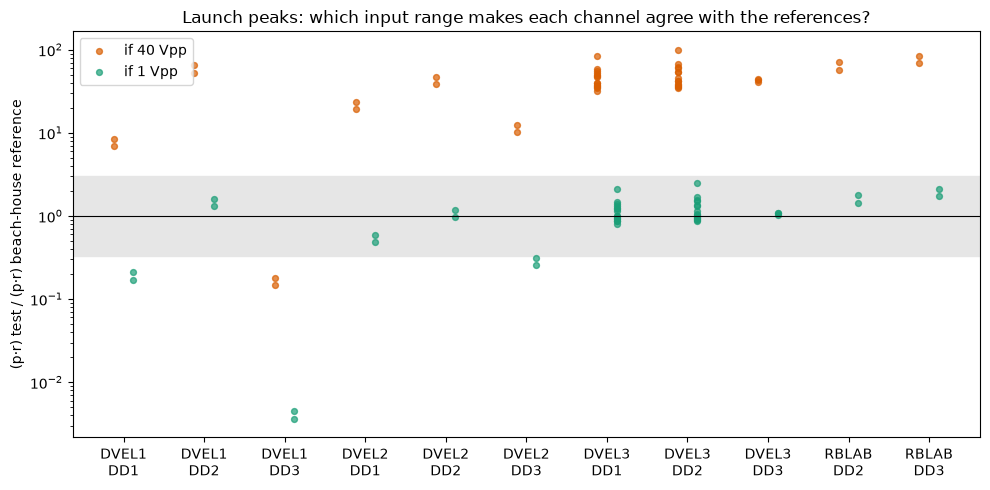

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
xt = []
for i, ((sta, cha), g) in enumerate(test.groupby(["station", "channel"])):
    for vpp, col, dx in ((40, "#d95f02", -0.12), (1, "#1b9e77", 0.12)):
        r = pd.concat([g.get(f"ratio_{vpp}Vpp_vs_BCHH2", pd.Series(dtype=float)), g.get(f"ratio_{vpp}Vpp_vs_BCHH1", pd.Series(dtype=float))]).dropna()
        ax.scatter(np.full(len(r), i + dx), r, color=col, s=18, alpha=0.7, label=f"if {vpp} Vpp" if i == 0 else None)
    xt.append(f"{sta}\n{cha}")
ax.axhspan(1 / 3, 3, color="0.9", zorder=0)
ax.axhline(1, color="k", lw=0.8)
ax.set(yscale="log", xticks=range(len(xt)), xticklabels=xt, ylabel="(p·r) test / (p·r) beach-house reference",
       title="Launch peaks: which input range makes each channel agree with the references?")
ax.legend()
fig.tight_layout(); fig.savefig(OUT / "launch_ratio.png", dpi=200)

## 3. Ambient level (night, 0.15–0.35 Hz)

RMS raw counts over two quiet hours (05:00–07:00 UTC, ~midnight local) on days the station
recorded, converted to Pa under each hypothesis. Typical microbarom/background levels in this band are
~0.01–0.5 Pa; BCHH sits on the beach and also hears surf, so it reads high. A channel showing ~1 count
whatever the hour is disconnected (digitizer noise).

In [8]:
def band_rms(sta, cha, t0, t1, band=(0.15, 0.35)):
    st = sds.get_waveforms("1R", sta, "*", cha, t0, t1)
    if not st:
        return np.nan
    st.merge(fill_value=0); tr = st[0]
    if tr.stats.npts < 0.8 * (t1 - t0) * tr.stats.sampling_rate:
        return np.nan
    tr.detrend("demean"); tr.taper(0.05)
    tr.filter("bandpass", freqmin=band[0], freqmax=band[1], corners=4, zerophase=True)
    k = int(120 * tr.stats.sampling_rate)
    return float(np.sqrt(np.mean(tr.data[k:-k].astype(float) ** 2)))

AMB_DAYS = {"DVEL1": ["2018-02-07"], "DVEL2": ["2018-02-07"], "RBLAB": [],
            "DVEL3": ["2019-03-01", "2019-04-01", "2019-05-20", "2019-06-15", "2019-08-15", "2019-10-01"],
            "BCHH1": ["2019-04-01", "2019-05-20", "2019-08-15"], "BCHH2": ["2019-04-01", "2019-05-20", "2019-08-15"]}
amb = []
for sta, days in AMB_DAYS.items():
    chans = TEST.get(sta) or [c for (s, c) in REFS if s == sta]
    for day in days:
        t0 = UTCDateTime(day + "T05:00:00")
        for cha in chans:
            try:
                v = band_rms(sta, cha, t0, t0 + 7200)
            except Exception:
                v = np.nan
            amb.append(dict(station=sta, channel=cha, day=day, rms_counts=v, Pa_if_40Vpp=v / GAIN[40], Pa_if_1Vpp=v / GAIN[1]))
amb = pd.DataFrame(amb)
amb.to_csv(OUT / "ambient_levels.csv", index=False)
amb.groupby(["station", "channel"])[["rms_counts", "Pa_if_40Vpp", "Pa_if_1Vpp"]].median().style.format("{:.3g}")

### DVEL1 HD1–HD6 (100 sps)

`KSC.xml` also lists `HD1–HD6` at DVEL1 (100 sps) and the SDS has them. Before 2026 only Centaurs were used,
so these should be a second (100 sps) stream of the same six inputs as `DD1–DD6`. If so, their launch peak in
counts should match the DD channel with the same number, and they take the same setting.

**Result (2018-02-06 run):** HD1–HD6 hold data only for the early hours of 2018-02-06, before the
DD stream started, and nothing during the launch, so they cannot be compared. They carry no launch
signal; the StationXML can keep them on the DD setting (1 Vpp for live inputs) or drop that epoch.

In [9]:
t0 = UTCDateTime("2018-02-06T20:45:00")
hd = []
for i in range(1, 7):
    row = dict(input=i)
    for band in ("DD", "HD"):
        try:
            pk, nz = peak_counts("DVEL1", f"{band}{i}", t0)
        except Exception:
            pk, nz = np.nan, np.nan
        row[f"{band}_peak_counts"], row[f"{band}_snr"] = pk, pk / nz if nz else np.nan
    row["HD/DD"] = row["HD_peak_counts"] / row["DD_peak_counts"]
    hd.append(row)
pd.DataFrame(hd).style.format(precision=2)

,input,DD_peak_counts,DD_snr,HD_peak_counts,HD_snr,HD/DD
0,1,16601.54,102.76,nan,nan,nan
1,2,127718.00,1143.44,nan,nan,nan
2,3,354.50,6.00,nan,nan,nan
3,4,46.90,0.89,nan,nan,nan
4,5,49.43,1.07,nan,nan,nan
5,6,52.32,1.09,nan,nan,nan


## 4. Verdict and proposed metadata

In [10]:
verdict = summ.set_index(["station", "channel"])
amb_med = amb.groupby(["station", "channel"]).rms_counts.median()
EPOCHS = {  # from KSC.xml / master sheet
    "DVEL1": ("2018-02-06", "2018-02-08"), "DVEL2": ("2018-02-06", "2018-02-08"),
    "RBLAB": ("2018-02-06", "2018-02-08"), "DVEL3": ("2019-02-13", "2020-01-31"),
}
dvel3_meta = stages[(stages.station == "DVEL3") & stages.channel.str.startswith("HD")]
rows = []
for sta, chans in TEST.items():
    for cha in chans:
        v = verdict.loc[(sta, cha)] if (sta, cha) in verdict.index else None
        live = (v is not None) or (amb_med.get((sta, cha), np.nan) > 3)
        evid = []
        if v is not None:
            evid.append(f"launches n={int(v.n_launches)}: median ratio {v.median_ratio_if_1Vpp:.2f} if 1 Vpp vs {v.median_ratio_if_40Vpp:.0f} if 40 Vpp")
        if sta == "DVEL3" and len(dvel3_meta):
            evid.append("Centaur 166 dataless (2019-06-25): preamp x40 on HD1-HD3")
        a = amb_med.get((sta, cha), np.nan)
        if not np.isnan(a):
            evid.append(f"night 0.15-0.35 Hz: {a:.1f} counts = {a / 736:.3f} Pa if 1 Vpp / {a / 18.4:.2f} Pa if 40 Vpp")
        if v is not None and v.median_ratio_if_1Vpp < 0.05:     # no launch signal under either setting
            vpp, live = np.nan, False
            evid.insert(0, "no launch signal: dead or disconnected")
        elif v is not None:
            vpp = 1 if v.launch_verdict == "1 Vpp" else 40
        elif sta == "DVEL3":
            vpp = 1
        else:
            vpp = np.nan
        rows.append(dict(network="1R", station=sta, location="00", channel=cha, start=EPOCHS[sta][0], end=EPOCHS[sta][1],
                         vpp_in_KSC_xml=40, proposed_vpp=vpp, proposed_counts_per_Pa=GAIN.get(vpp, np.nan),
                         channel_live=bool(live), evidence="; ".join(evid)))
audit = pd.DataFrame(rows)
audit.to_csv(REPO_ROOT / "03_stationxml" / "vpp_audit_DVEL_RBLAB.csv", index=False)
audit

,network,station,location,channel,start,end,vpp_in_KSC_xml,proposed_vpp,proposed_counts_per_Pa,channel_live,evidence
0,1R,DVEL1,00,DD1,2018-02-06,2018-02-08,40,1.0,736.0,True,launches n=1: median ratio 0.19 if 1 Vpp vs 8 ...
1,1R,DVEL1,00,DD2,2018-02-06,2018-02-08,40,1.0,736.0,True,launches n=1: median ratio 1.47 if 1 Vpp vs 59...
2,1R,DVEL1,00,DD3,2018-02-06,2018-02-08,40,NaN,NaN,False,no launch signal: dead or disconnected; launch...
3,1R,DVEL1,00,DD4,2018-02-06,2018-02-08,40,NaN,NaN,False,night 0.15-0.35 Hz: 1.6 counts = 0.002 Pa if 1...
4,1R,DVEL1,00,DD5,2018-02-06,2018-02-08,40,NaN,NaN,False,night 0.15-0.35 Hz: 1.4 counts = 0.002 Pa if 1...
5,1R,DVEL1,00,DD6,2018-02-06,2018-02-08,40,NaN,NaN,False,night 0.15-0.35 Hz: 2.3 counts = 0.003 Pa if 1...
6,1R,DVEL2,00,DD1,2018-02-06,2018-02-08,40,1.0,736.0,True,launches n=1: median ratio 0.54 if 1 Vpp vs 22...
7,1R,DVEL2,00,DD2,2018-02-06,2018-02-08,40,1.0,736.0,True,launches n=1: median ratio 1.07 if 1 Vpp vs 43...
8,1R,DVEL2,00,DD3,2018-02-06,2018-02-08,40,1.0,736.0,True,launches n=1: median ratio 0.28 if 1 Vpp vs 11...
9,1R,RBLAB,00,DD1,2018-02-06,2018-02-08,40,NaN,NaN,False,
